<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG102 - Análisis de datos en Geología**</span>

Bienvenido al curso!!!

Vamos a revisar ejemplos de <span style="color:gold">análisis de datos</span> en Geología usando código en Python. <br>
Es necesario que tengas un conocimiento previo en programación con Python, estadística y geología general.


<span style="color:gold; font-size:20px">**Análisis descriptivo** </span>

***
- [¿Qué es el análisis descriptivo?](#parte-1)
- [Procesamiento de datos](#parte-2)
- [Caso de estudio: ocurrencia de terremotos cercanos a Lima](#parte-3)
- [Visualización 3D con Plotly](#parte-4)

***

Vamos a seguir la transformación de los datos: **archivo → tipos y nombres de columnas → distancias → filtro → agrupación → figura**. Antes de ejecutar cada celda, identifica qué tabla usa, qué cambia y qué resultado esperas. Si usas IA para proponer código, comprueba esos pasos con los datos y las unidades del ejemplo.

### <span style="color:gold">**Antes de ejecutar**</span>

En JupyterLite, ejecuta la siguiente celda y espera a que termine la preparación. En Python local, instala las librerías con `%pip install seaborn==0.13.2 plotly==6.5.2 "nbformat>=5,<6" geopy==2.4.1 openpyxl==3.1.5`. Los archivos de entrada deben estar en la carpeta `files`, junto al notebook.


In [ ]:
import sys
# Preparar las librerías del navegador antes de continuar.
if sys.platform == "emscripten":
    import piplite
    await piplite.install(['seaborn==0.13.2', 'plotly==6.5.2', 'nbformat>=5,<6', 'geopy==2.4.1', 'openpyxl==3.1.5'])
    from pyodide_js import loadPackage
    await loadPackage("ssl") # Geopy importa este módulo de la biblioteca estándar.


<a id="parte-1"></a>

### <span style="color:lightgreen">**¿Qué es el análisis descriptivo?**</span>
***

De acuerdo con el [Glosario IT de Gartner](https://www.gartner.com/en/information-technology/glossary/descriptive-analytics#:~:text=Descriptive%20Analytics%20is%20the%20examination,%2C%20tables%2C%20or%20generated%20narratives.), el análisis descriptivo es la primera fase del **análisis de datos**. <br>
Consiste en **examinar** los datos con el fin de responder a la pregunta **¿qué ha sucedido?** o **¿qué está sucediendo?**.

En esta fase, los datos generados en tiempo real e históricos se analizan a través de métodos estadísticos simples y técnicas de visualización. Es común reportar los resultados de esta fase a través de reportes, resúmenes o dashboards.




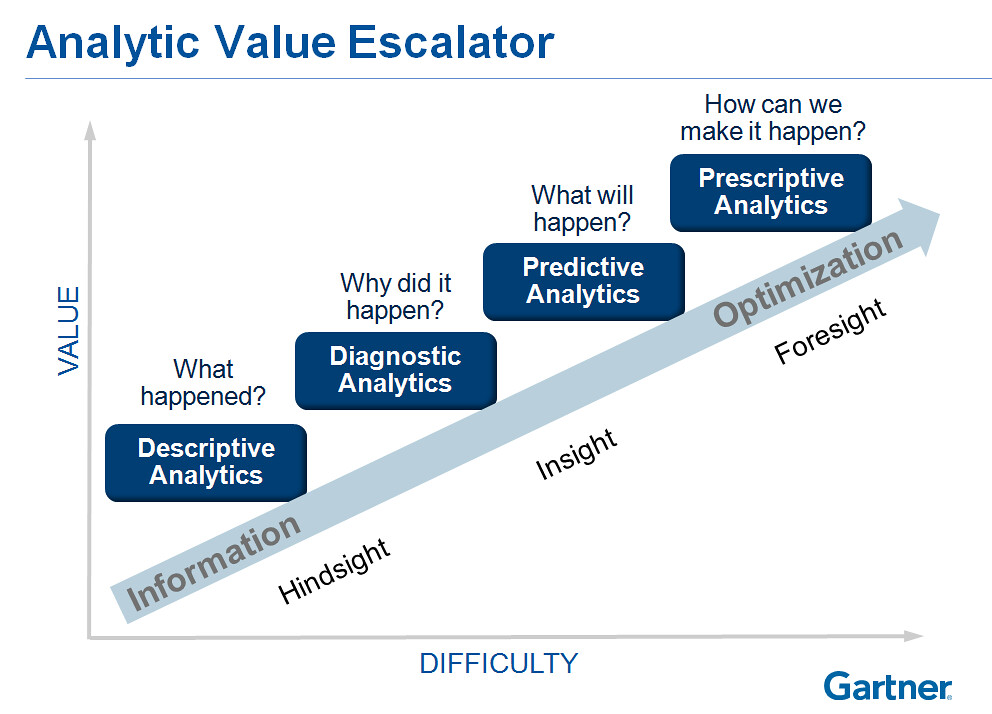




Antes de empezar con el código, mencionaremos algunas de las ventajas de usar Python en el análisis de datos:
    
- Aprender a programar te permite desarrollar tus habilidades analíticas y de resolución de problemas.
- Puedes crear e implementar diferentes herramientas de manera independiente y usarlas en cada etapa del análisis de datos.
- <span style="color:gold">Python</span> es uno de los lenguajes más usados en <span style="color:lightgreen">Ciencia de Datos</span> e <span style="color:lightgreen">Inteligencia Artificial</span> debido a su sintáxis sencilla y clara escritura.
- Todos los trabajos realizados en <span style="color:gold">Python</span> son flexibles y escalables.

***

<a id="parte-2"></a>

### <span style="color:lightgreen">**Procesamiento de datos**</span>
***

Usaremos un archivo Excel perteneciente a la base de datos del **IGP (Instituto Geofísico del Perú)**. <br>
Específicamente, la información que contiene describe la <span style="color:#43c6ac">ocurrencia de terremotos en Perú desde 1960 hasta 2021</span>.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set(style="ticks", context="talk") # Mejor calidad visual
plt.style.use("dark_background") # Gráficos con fondo oscuro
import plotly.io as pio
pio.renderers.default = "plotly_mimetype"


Empezaremos usando la función `read_excel` para leer el archivo ubicado en la carpeta `files`. <br>
Asignaremos la información a un DataFrame de nombre `data`.

In [ ]:
data = pd.read_excel("files/sismos.xlsx")

El tamaño de filas y columnas en la tabla se puede observar usando el atributo `shape`:

In [ ]:
data.shape

La tabla contiene 6 columnas y casi 19,000 filas.

Observamos las primeras 5 filas de `data` usando el método `head`:

In [ ]:
data.head()

Mostramos el tipo de datos de cada columna usando el atributo `dtypes`:

In [ ]:
data.dtypes

O también podemos usar el método `info`:

In [ ]:
data.info()

Notaremos que la tabla contiene los siguientes datos:

- `fecha UTC` : fecha de ocurrencia del terremoto, en **string**.
- `hora UTC` : hora de ocurrencia del terremoto, en **string**.
- `latitud (º)` : latitud del epicentro, en **float**.
- `longitud (º)` : longitud del epicentro, en **float**.
- `profundidad (km)` : profundidad del epicentro, en **integer**.
- `magnitud (M)` : magnitud del terremoto, en **float**.

No usaremos la columna de hora, así que la eliminaremos usando el método `drop`. <br>
Activaremos el parámetro `inplace=True` para que los cambios se guarden en la tabla.

In [ ]:
data.drop(columns=["hora UTC"], inplace=True)

In [ ]:
data.head()

Ahora, renombraremos las columnas para facilitar su uso dentro del código. <br>
Primero, crearemos un diccionario que contenga los nombres de las columnas y los nombres que usaremos para reemplazarlos:

In [ ]:
cols = {"fecha UTC": "Fecha", "latitud (º)": "Latitud",
        "longitud (º)": "Longitud", "profundidad (km)": "Profundidad",
        "magnitud (M)": "Magnitud"}
print(cols)


Ahora, usaremos el método `rename`:

In [ ]:
data.rename(columns=cols, inplace=True)

In [ ]:
data.head()

Ahora, transformaremos el dato de las fechas de **string** a **datetime**:

> En Python, **datetime** es un objeto que representa una fecha.

Seleccionamos la columna con las fechas:

In [ ]:
fecha = data["Fecha"]

In [ ]:
fecha.head(10) # Muestra las 10 primeras filas

Y usaremos la función `to_datetime` para transformarlo en **datetime**:

In [ ]:
data["Fecha"] = pd.to_datetime(fecha, format="%d/%m/%Y")

Verificamos:

In [ ]:
data.head()

In [ ]:
data.dtypes

<a id="parte-3"></a>

### <span style="color:lightgreen">**Caso de estudio: ocurrencia de terremotos cercanos a Lima**</span>
***

Vamos a analizar los terremotos ocurridos cerca a Lima, en un radio de 150 kilómetros.

Empezaremos usando la librería `geopy` para seleccionar aquellos epicentros que se encuentren dentro del radio mencionado:

In [ ]:
from geopy.distance import geodesic

Empezaremos asignando un punto de referencia para el centro de la ciudad de Lima:

In [ ]:
centro = (-12.045976, -77.030555) # Centro de la ciudad de Lima

Seleccionamos las columnas de latitud y longitud de cada epicentro y calcumos su distancia geodésica (en km) al punto de Lima:

In [ ]:
# Columnas de coordenadas geográficas
latlon = data[["Latitud", "Longitud"]]

# Calculamos la distancia geodésica a Lima para cada fila
distancia = latlon.apply(lambda punto: geodesic(centro, punto).km, axis=1)
distancia.head()

Si establecemos un valor de 150 km como radio, podemos extraer los epicentros que estamos buscando:

In [ ]:
# Una serie de valores numéricos al ser evaluada con una 
# expresión lógica, devuelve una serie de valores lógicos
distancia <= 150

Vamos a guardar la tabla filtrada en una variable llamada `lima` y crearemos una copia para no alterar el original:

In [ ]:
lima = data[distancia <= 150].reset_index(drop=True).copy()

Antes de continuar, lee el filtro: `distancia <= 150` produce un valor lógico por fila, y `data[...]` conserva las filas verdaderas. ¿Un epicentro a exactamente 150 km queda incluido? La distancia es geodésica al epicentro; no incluye la profundidad del foco.

Observamos la nueva tabla:

In [ ]:
lima.head()

También podemos ver un resumen estadístico de la tabla usando el método `describe`:

In [ ]:
lima.describe().T

Y mostramos el registro de sismos cercanos a Lima:

In [ ]:
print(f"Se registraron {len(lima)} sismos en un radio de 150 km en torno a Lima.")

Vamos a crear un gráfico que muestre la distribución de los epicentros en torno a la ciudad de Lima. Usaremos Plotly para crear una figura interactiva:

Usaremos el mapa para ubicar registros. Los mosaicos del mapa base requieren conexión a Internet. El catálogo reúne muchos años de observación y puede tener cambios de cobertura y completitud; un mayor conteo no equivale por sí solo a una mayor tasa física ni a una predicción.

In [ ]:
# Crear el gráfico de dispersión con mapa base
fig = px.scatter_map(
    data_frame=lima,
    lat="Latitud",
    lon="Longitud",
    zoom=7,  # Nivel de zoom
    center=dict(lat=centro[0], lon=centro[1]),  # Centro del mapa
    map_style="open-street-map",  # Estilo del mapa
)

# Modificar el layout del gráfico
fig.update_layout(
    width=None,                           # Ancho en píxeles
    height=700,                           # Alto en píxeles
    template="plotly_dark",               # Tema del gráfico
    margin=dict(l=30, r=30, t=40, b=30),  # Márgenes del gráfico
)

# Modificar los detalles del gráfico de puntos
fig.update_traces(
    marker=dict(
        size=6,         # Tamaño
        opacity=0.7,    # Opacidad
    )
)

# Agregar una anotación para el texto personalizado
fig.add_annotation(
    text="<b>Mapa de ocurrencia de sismos</b><br>Ubicación: Lima<br>Radio de influencia: 150 km<br>Generado en Plotly",
    xref="paper", yref="paper",
    x=0.01, y=0.95,                    # Coordenadas relativas al gráfico
    showarrow=False, 
    font=dict(size=16, color="black"), # Fuente del texto
    align="left",                      # Alineación del texto
    bgcolor="white",                   # Color del cuadro de texto
    bordercolor="black",               # Color de la línea del borde
    borderwidth=1,                     # Grosor de la línea del borde
    borderpad=5                        # Márgenes del cuadro de texto
)

# Mostrar el gráfico
fig.show()

Con la información presente, trataremos de responder las siguientes preguntas (usando un gráfico en cada pregunta):

- ¿Cuántos terremotos ocurrieron por año?

- ¿Con qué frecuencia ocurrieron terremotos en cada mes? ¿Qué mes tiene la mayor frecuencia de terremotos?

- ¿Cuál es la distribución de profundidad de los sismos sobre el área de Lima?

***
<span style="color:gold"> **¿Cuántos terremotos ocurrieron por año?** </span>

Empezaremos revisando los datos generales:

In [ ]:
lima.head()

In [ ]:
# Ejemplo de extracción del año de ocurrencia para una fila de la tabla
lima.loc[0, "Fecha"].year

Para observar la frecuencia de terremotos que ocurrieron por año, usaremos un **diagrama de barras**.

> Para determinar la **frecuencia de terremotos por año**, tendremos que agrupar los datos de acuerdo al año en que ocurrieron.

Empezaremos extrayendo el año de ocurrencia de cada terremoto. Usaremos el atributo `year` de la columna `Fecha`:

In [ ]:
lima["Fecha"].apply(lambda fecha: fecha.year)

Y la asignaremos a una nueva columna llamada `Año`:

In [ ]:
lima["Año"] = lima["Fecha"].apply(lambda fecha: fecha.year)

Revisando nuevamente los datos generales:

In [ ]:
lima.head()

Ahora, agruparemos los terremotos de acuerdo al año de ocurrencia.

> Usaremos el método `groupby` para agrupar los datos y `count` para obtener las frecuencias por año.

In [ ]:
# Muestra los primeros 10 resultados
lima.groupby("Año")["Año"].count().head(10)

Asignaremos esta información a una variable llamada `conteo`:

In [ ]:
conteo = lima.groupby("Año")["Año"].count()
conteo = conteo.reindex(range(lima["Año"].min(), lima["Año"].max() + 1), fill_value=0)


Y extraeremos los datos necesarios para plotear el diagrama de barras:

In [ ]:
x = list(conteo.index)       # Año
height = list(conteo.values) # Cantidad de sismos

Para terminar, usaremos la función `bar` y los datos en `frecuencia` y `años` para crear el diagrama de barras:

In [ ]:
# Figura principal
fig, ax = plt.subplots(figsize=(10, 4.5))

# Diagrama de barras
ax.bar(x=x, height=height, color="lightgreen", alpha=0.75, edgecolor="black")

# Agregamos detalles
ax.set_title("Frecuencia de terremotos por año\n Fuente: IGP", fontsize=16)
ax.set_xlabel("Año", fontsize=14)
ax.set_ylabel("Frecuencia", fontsize=14)

# Cambiamos la ubicación de los ticks en el eje X
ax.set_xticks([1965, 1975, 1985, 1995, 2005, 2015])

plt.show()

***
<span style="color:gold"> **¿Con qué frecuencia ocurrieron terremotos en cada mes? ¿Qué mes tiene la mayor frecuencia de terremotos?** </span>

Para observar la frecuencia de terremotos por mes, usaremos nuevamente un **diagrama de barras**. <br>
Para determinar la **frecuencia de terremotos por mes**, tendremos que agrupar los datos de acuerdo al mes en que ocurrieron.

Empezaremos extrayendo el mes de ocurrencia de cada terremoto. Para esto usaremos el atributo `month` de la columna `Fecha`, y asignaremos esta serie a una nueva columna llamada `Mes`:

In [ ]:
lima["Mes"] = lima["Fecha"].apply(lambda fecha: fecha.month)

Revisamos los datos generales:

In [ ]:
lima.head()

Ahora, agruparemos los terremotos de acuerdo al mes de ocurrencia usando el método `groupby` y `count` para obtener las frecuencias por mes. 

Asignaremos esta información a una variable llamada `conteo`:

In [ ]:
conteo = lima.groupby("Mes")["Mes"].count().reindex(range(1, 13), fill_value=0)


Crearemos una lista con los meses de ocurrencia, y otra lista con las frecuencias:

In [ ]:
x = list(conteo.index)       # Mes
height = list(conteo.values) # Cantidad de sismos

Ahora, crearemos el diagrama de barras usando la función `bar` y los datos `frecuencia` y `mes`:

In [ ]:
# Figura principal
fig, ax = plt.subplots(figsize=(10, 5))

# Diagrama de barras
barra = ax.bar(x=x, height=height, color="lightgreen", alpha=0.75, edgecolor="black")

# Título
ax.set_title("Frecuencia de terremotos por mes\n Fuente: IGP", fontsize=18)

# Cambiar los ticks del eje X por el nombre de cada mes
labels = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
plt.xticks(ticks=x, labels=labels, fontsize=14)

# Colocar la frecuencia encima de cada barra
ax.tick_params(left=False, labelleft=False, bottom=False)

for spine in ax.spines.values():
    spine.set_visible(False)

for bar in barra:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 1,
            str(int(bar.get_height())),
            ha="center", fontsize=14)

# Mostrar la figura
plt.show()

Lee las frecuencias en las barras. ¿Qué mes tiene el mayor conteo y hay meses empatados? Este resumen corresponde al catálogo y al filtro utilizados; no demuestra que un mes cause más sismos ni permite predecir el siguiente evento.


***
<span style="color:gold"> **¿Cuál es la distribución de profundidad de los sismos sobre el área de Lima?** </span>

Empezaremos observando la distribución de profundidad a través de un **histograma**.

Usaremos la columna de `Profundidad` y la función `hist`:

In [ ]:
# Figura principal
fig, ax = plt.subplots(figsize=(10, 4.5))

# Histograma
ax.hist(lima["Profundidad"], bins=30, color="lightgreen", alpha=0.8, edgecolor="black")

# Título y ticks
ax.set_title("Distribución de profundidad de los sismos (en km)", fontsize=15)
ax.set_xticks(ticks=[20*i for i in range(0, 9)], labels=[20*i for i in range(0, 9)], fontsize=13)

# Grilla
ax.grid(lw=0.5, alpha=0.5)
ax.set_axisbelow(True)

# Mostrar la figura
plt.show()

Vamos a separar las profundidades usando 50 km y 100 km como límites didácticos. Son decisiones de clasificación, no modas detectadas automáticamente por el código.

Usaremos una función llamada `clase_profundidad` para establecer un color de acuerdo a la profundidad de ocurrencia del sismo:

In [ ]:
def clase_profundidad(profundidad):
    if profundidad <= 50:
        return "Hasta 50 km"
    elif 50 < profundidad <= 100:
        return "Mayor a 50 y hasta 100 km"
    elif profundidad > 100:
        return "Mayor a 100 km"

# Paleta de colores
palette = {"Hasta 50 km": "red",
           "Mayor a 50 y hasta 100 km": "gold",
           "Mayor a 100 km": "green"}

Aplicando la función a la columna `Profundidad` y asignando el resultado a una nueva columna llamada `Clase`:

In [ ]:
lima["Clase"] = lima["Profundidad"].apply(clase_profundidad)

Observamos los datos generales:

In [ ]:
lima.head()

Y ahora, graficaremos la distribución de profundidad usando un **diagrama de dispersión** y agregaremos los datos de color generados anteriormente:

In [ ]:
# Crear el gráfico de dispersión con mapa base
fig = px.scatter_map(
    data_frame=lima,
    lat="Latitud",
    lon="Longitud",
    color="Clase",
    color_discrete_map=palette,
    zoom=7,  # Nivel de zoom
    center=dict(lat=centro[0], lon=centro[1]),  # Centro del mapa
    map_style="open-street-map",  # Estilo del mapa
)

# Modificar el layout del gráfico
fig.update_layout(
    width=None,                            # Ancho en píxeles
    height=700,                            # Alto en píxeles
    template="plotly_dark",                # Tema del gráfico
    margin=dict(l=30, r=30, t=40, b=30),   # Márgenes del gráfico
    legend=dict(
        title="Profundidad",               # Título de la leyenda
        font=dict(size=14, color="black"), # Fuente del texto
        bgcolor="white",                   # Color de fondo de la leyenda
        x=0.01, y=0.75,                     # Ubicación de la leyenda
        bordercolor="black",               # Color de la línea del borde
        borderwidth=1                      # Márgenes del cuadro de texto
    )
)

# Modificar los detalles del gráfico de puntos
fig.update_traces(
    marker=dict(
        size=7,         # Tamaño
        opacity=0.7,    # Opacidad
    )
)

# Agregar una anotación para el texto personalizado
fig.add_annotation(
    text="<b>Mapa de ocurrencia de sismos</b><br>Ubicación: Lima<br>Radio de influencia: 150 km<br>Generado por Plotly",
    xref="paper", yref="paper",
    x=0.01, y=0.95,                    # Coordenadas relativas al gráfico
    showarrow=False, 
    font=dict(size=16, color="black"), # Fuente del texto
    align="left",                      # Alineación del texto
    bgcolor="white",                   # Color del cuadro de texto
    bordercolor="black",               # Color de la línea del borde
    borderwidth=1,                     # Grosor de la línea del borde
    borderpad=5                        # Márgenes del cuadro de texto
)

# Mostrar el gráfico
fig.show()

***

<a id="parte-4"></a>

### <span style="color:lightgreen">**Visualización 3D con `Plotly`**</span>
***
Para terminar, visualizaremos la información en 3D usando `plotly`, una librería de visualización interactiva:

In [ ]:
# Figura principal
fig = px.scatter_3d(
    data_frame=lima,
    x="Longitud", y="Latitud", z=lima["Profundidad"]*-1,
    color=lima["Clase"],
    color_discrete_map=palette
)

# Modificar el layout del gráfico
fig.update_layout(
    width=750,  # Ancho de figura
    height=500, # Alto de figura
    margin=dict(l=50,
            r=50,
            b=50,
            t=50,
            pad=4
           ),
    autosize=False,
    legend=dict(
        bgcolor="white",
        title="Profundidad",
        itemsizing="constant"
    ),
    paper_bgcolor="LightSteelBlue",
    scene=dict(xaxis_title="Longitud (°)",
               yaxis_title="Latitud (°)",
               zaxis_title="Profundidad (km)")
)

# Modificar los detalles del gráfico de puntos
fig.update_traces(marker={"size": 2})

fig.show()

Lee las unidades de los ejes: longitud y latitud están en grados; la profundidad está en kilómetros y se representa con signo negativo para situarla bajo la superficie. Esta figura no tiene una escala métrica uniforme entre los tres ejes. No midas distancias o inclinaciones directamente sobre ella.

Para exportar la figura 3D, podemos usar el método `write_html`:

In [ ]:
fig.write_html("sismos_3d.html")

***